# Simple Linear Regression

In [1]:
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

First step - we import the data from database, and we seperate the independent features from the dependent label. remember that the y is based on the x and this dataset has label ( hense we use supervises methods)

In [2]:
dataset = pd.read_csv('../Data/Salary_Data.csv')
# x = dataset[['YearsExperience']].values
x = dataset.iloc[:, :-1].values
y = dataset.iloc[:, -1].values

we first check out the distribution of the dataset

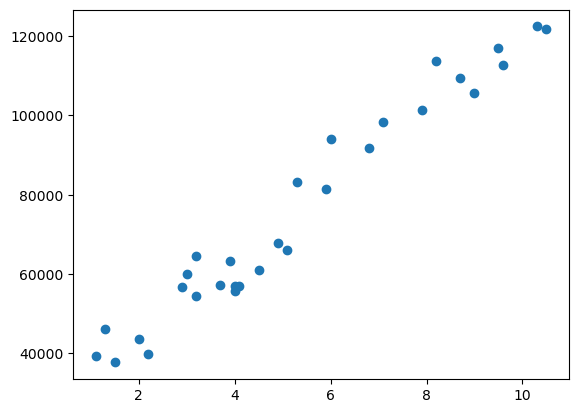

In [3]:
plt.scatter(x, y);

as we can see, the data is quite linear, hense we can do just fine with a linear regression model. we fit the train variables to our selected model ( we dont need to fit_transform as that changes the base dataset)

we seperate the test sets from train sets using `train_test_split` method. its acceptable to do something like 70-80% for training the model and leave 20%-30% out to test it out.  in this case we set the random_state to 0

In [4]:
from sklearn.model_selection import train_test_split
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=0)

In [5]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score

model = LinearRegression()
model.fit(x_train, y_train)

y_pred = model.predict(x_test)

print(r2_score(y_test, y_pred))
print(model.score(x_test, y_test))

0.988169515729126
0.988169515729126


as we can see, r2_score and model.score give the same value, both get the test splits but in different orders. hense we just stick to using model.score in this case. we see that the accuracy score of the model is in a normal range. after that, we fit the plot line on the scatter data

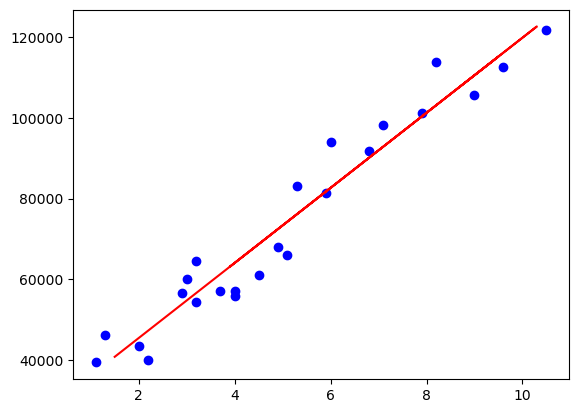

In [6]:
plt.scatter(x_train, y_train, color='blue')
plt.plot(x_test, model.predict(x_test), color='red')
plt.show()

we use a random number of years or ask the user for a number to give to a model to see what salary it predicts

In [7]:
# years = float(input("Enter YOE: "))
years = 10
predicted_salary = model.predict(np.array([[years]]))[0]
print(predicted_salary)

119905.85041792007


this dataset Advertising has 3 independent features. we test each ones accuracy (r2 score)

In [8]:
dataset = pd.read_csv('../Data/Advertising.csv')
dataset = dataset.drop(dataset.columns[0], axis=1)

x_tv = dataset[['TV']]
x_radio = dataset[['radio']]
x_newspaper = dataset[['newspaper']]
y = dataset.iloc[:, -1].values


def train_model(feature, name):
    x_train, x_test, y_train, y_test = train_test_split(feature, y, test_size=0.2, random_state=0)

    model = LinearRegression()
    model.fit(x_train, y_train)

    y_pred = model.predict(x_test)
    return f"R² score using {name}: {model.score(x_test, y_test):.4f}"

print(train_model(x_tv, 'TV'))
print(train_model(x_radio, 'Radio'))
print(train_model(x_newspaper, 'Newspaper'))


R² score using TV: 0.6763
R² score using Radio: 0.2298
R² score using Newspaper: -0.0212
